## Notebook with analysis examples of cosmological chains 

### 1. Loading the chains

In [15]:
# Loading necessary packages #

import numpy as np
import matplotlib.pyplot as plt
import getdist
from getdist import MCSamples, plots
import IPython
import matplotlib
import matplotlib.lines as mlines
import corner


In [31]:
# Loading the chains #

names = ['test_WL.npz', 'gp_WL_w0wa_DR1.npz', 'checkpoint_3x2pt_DR1_area_2000_realistic.npz', 'WL_LCDM.npz', 'WL_GP_LCDM.npz', 'checkpoint_gp_3x2pt.npz', 
         'GP_3x2pt_LCDM.npz', '3x2pt_LCDM.npz']
keys = ['w0wa_WL', 'w0wa_GP_WL', 'w0wa_3x2pt', 'LCDM_WL', 'LCDM_GP_WL', 'w0wa_GP_3x2pt', 'LCDM_GP_3x2pt', 'LCDM_3x2pt']

# Create a dictionary with all data #
dict_data = {}
path = '/home/jipdebuck/chains/'
for name, key in zip(names, keys):
    data = np.load(path + name, allow_pickle=True)
    dict_data.update({key: data})

# Create a dictionary with chains only #
dict_chains = {}
for key in dict_data.keys():
    chain_dict = dict_data[key]["chain"].item()   
    dict_chains.update({key: chain_dict})

In [22]:
# Accessing posterior for a specific chain and parameter #
print(dict_chains["w0wa_WL"]["Omega_b0"])

# Accessing weights or parameter names for a specific chain #
print(dict_data["w0wa_WL"]["weights"])
print(dict_data["w0wa_GP_WL"]["param_names"])

[0.04424136 0.08378785 0.02280671 ... 0.07326373 0.09031372 0.0949385 ]
[-3.16655028e+05            -inf            -inf ... -1.36612825e+01
 -1.33880800e+01 -1.43927792e+01]
['Omega_b0' 'Omega_cdm0' 'logAs' 'ns' 'H0' 'AIA' 'EtaIA' 'w0' 'wa'
 'multiplicative_bias_1' 'multiplicative_bias_2' 'multiplicative_bias_3'
 'multiplicative_bias_4' 'multiplicative_bias_5' 'multiplicative_bias_6'
 'x1' 'x2' 'x3' 'x4' 'x5' 'x6' 'y1' 'y2' 'y3' 'y4' 'y5' 'y6' 'corr_len']


### 2. Plotting chains using corner

In [34]:
names_chain = ['Omega_b0', 'Omega_cdm0', 'logAs', 'ns', 'H0', 'EtaIA', 'w0', 'wa']
points = np.column_stack([dict_chains["w0wa_WL"][p] for p in names_chain])
points_gp = np.column_stack([dict_chains["w0wa_GP_WL"][p] for p in names_chain])
log_w = dict_data["w0wa_WL"]["weights"]
log_w_gp = dict_data["w0wa_GP_WL"]["weights"]

#samples = MCSamples(samples=points, weights=np.exp(dict_data["w0wa_WL"]["weights"]), names=names_chain, labels=names_chain)
#g = plots.get_subplot_plotter()
#g.settings.smooth_scale_1D = 0
#g.settings.smooth_scale_2D = 0
#g.settings.axis_limits = {"Omega_cdm0": (0.11, 0.37)}
#g.triangle_plot([samples], filled=True, bins=20)

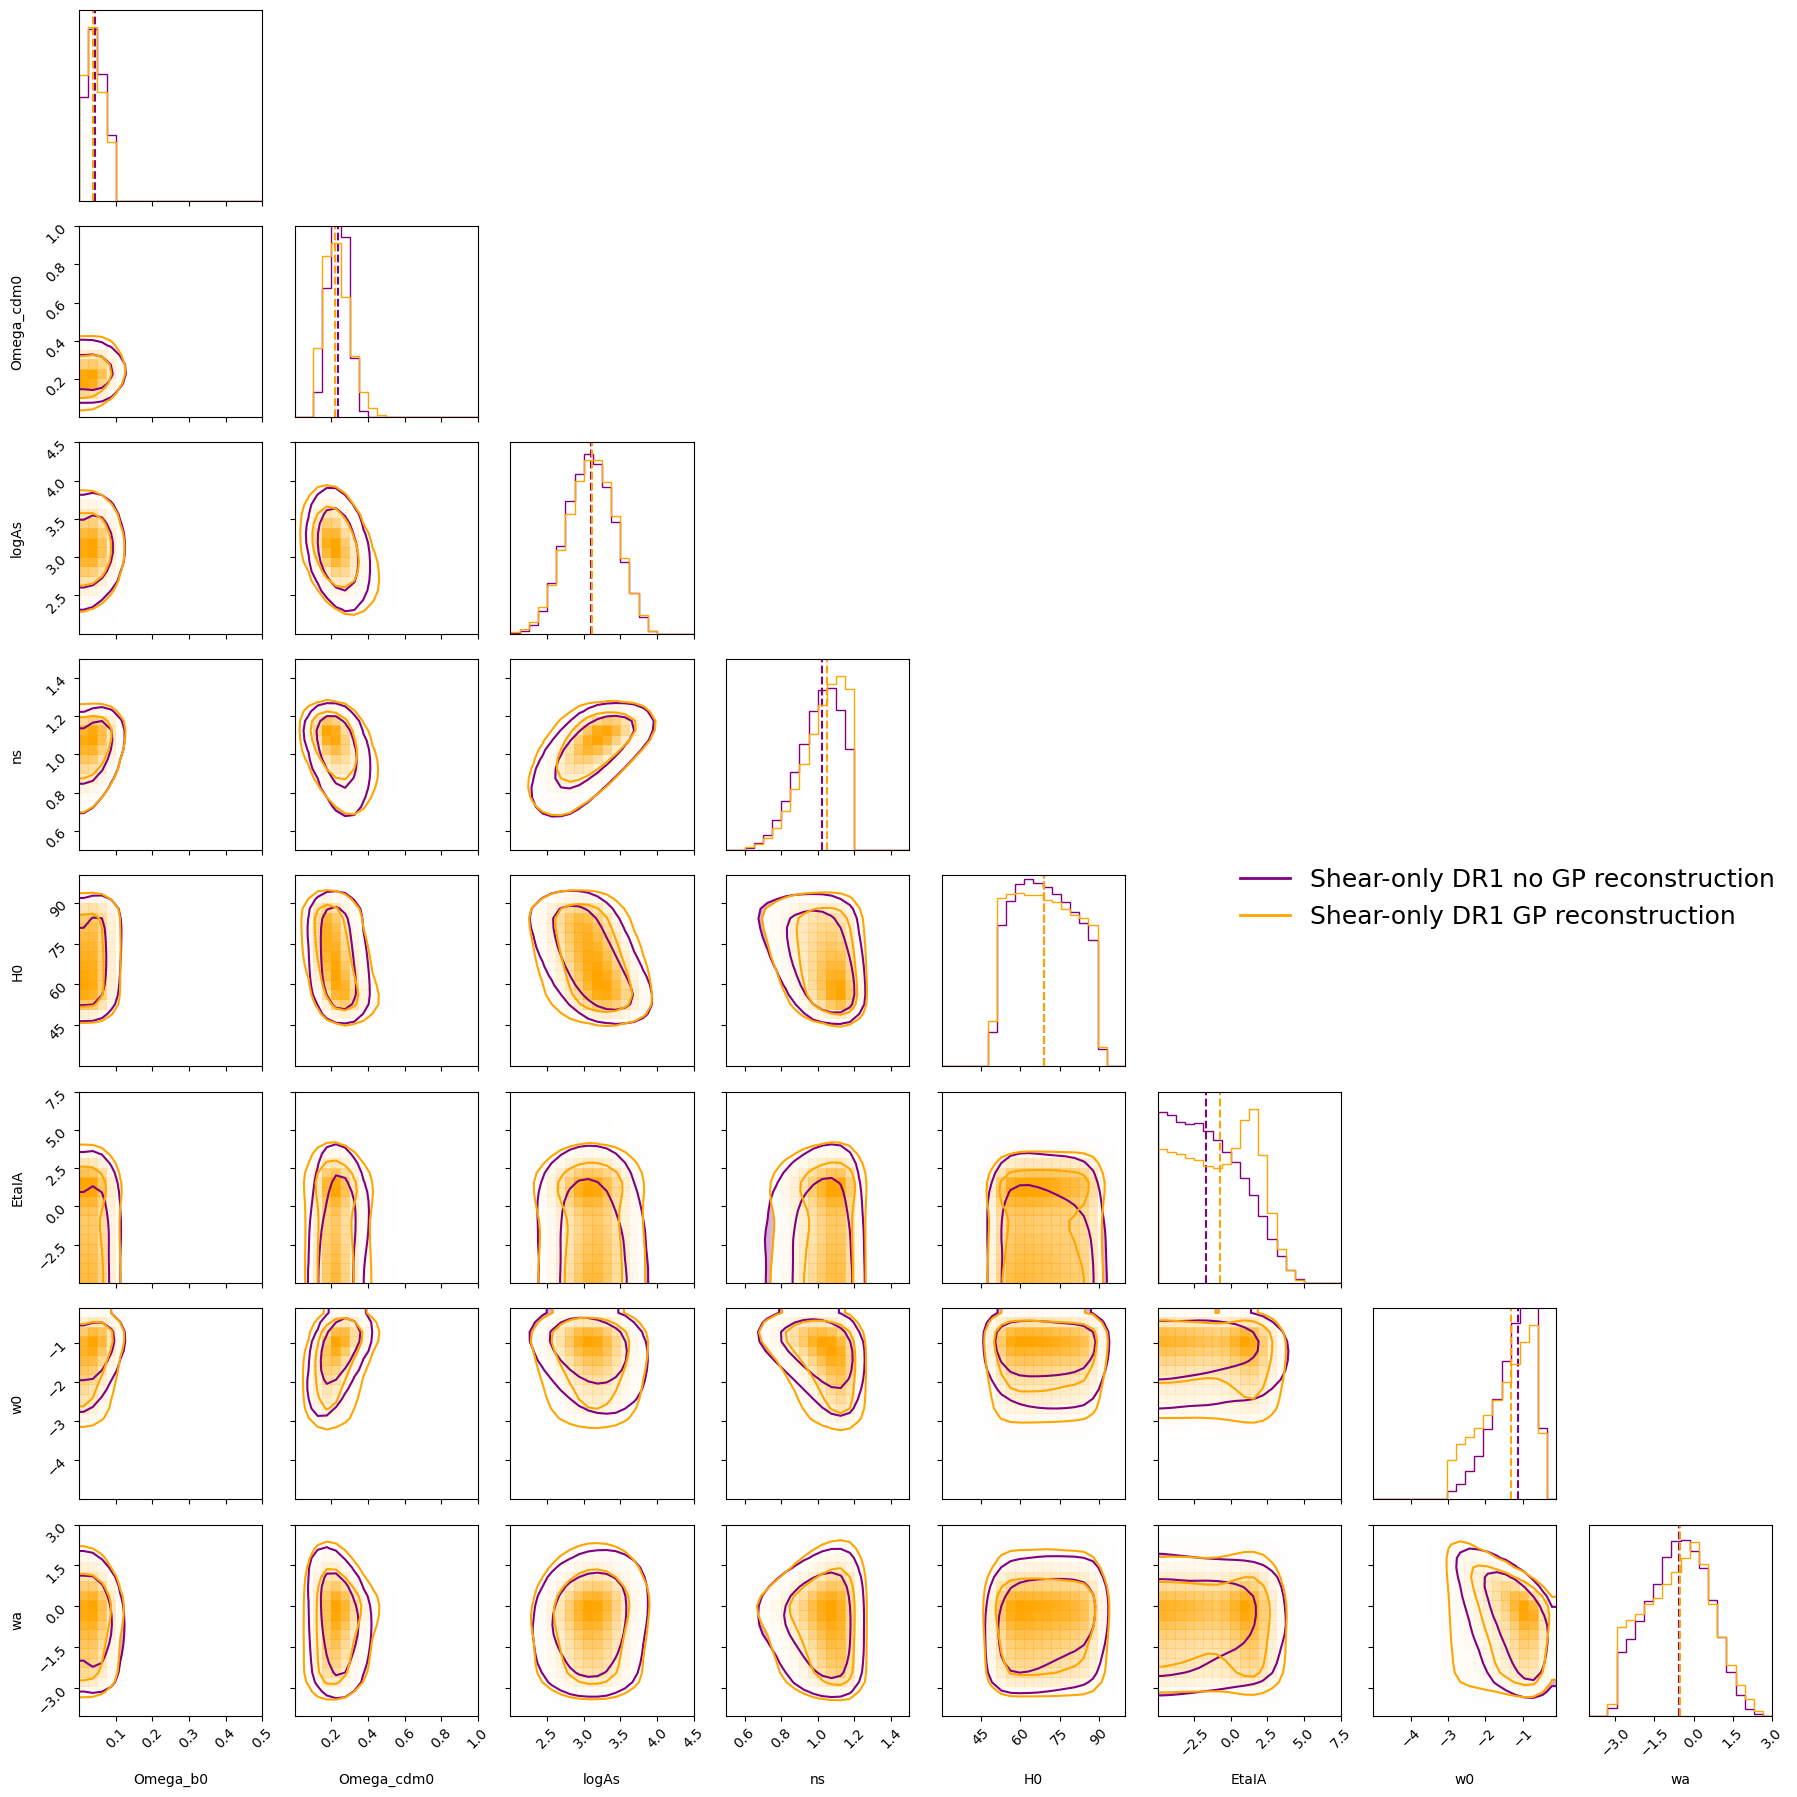

In [43]:
# Plotting WL GP and no GP posteriors in a single corner plot using corner #

range_WL = [(0, 0.5), (0, 1), (2, 4.5), (0.5, 1.5), (30, 100), (-5, 7.5), (-5, -0.1), (-4,3)]
fig = corner.corner(
    points, weights=np.exp(log_w), bins=20, labels=names_chain, color='purple', linewidth=2,
    plot_datapoints=False, fill_contours=True, smooth=1.0, quantiles=[0.5], range=range_WL, levels=(0.68, 0.95))
corner.corner(
    points_gp, weights=np.exp(log_w_gp), bins=20, color='orange', labels=names_chain, linewidth=2,
    plot_datapoints=False, fill_contours=False, smooth=1.0, quantiles=[0.5], range=range_WL, levels=(0.68, 0.95), fig=fig)
line1 = mlines.Line2D([], [], color="purple", lw=2, label="Shear-only DR1 no GP reconstruction")
line2 = mlines.Line2D([], [], color="orange", lw=2, label="Shear-only DR1 GP reconstruction")
fig.legend(
    handles=[line1, line2],
    loc="center right",
    frameon=False, fontsize=18
)
plt.tight_layout()

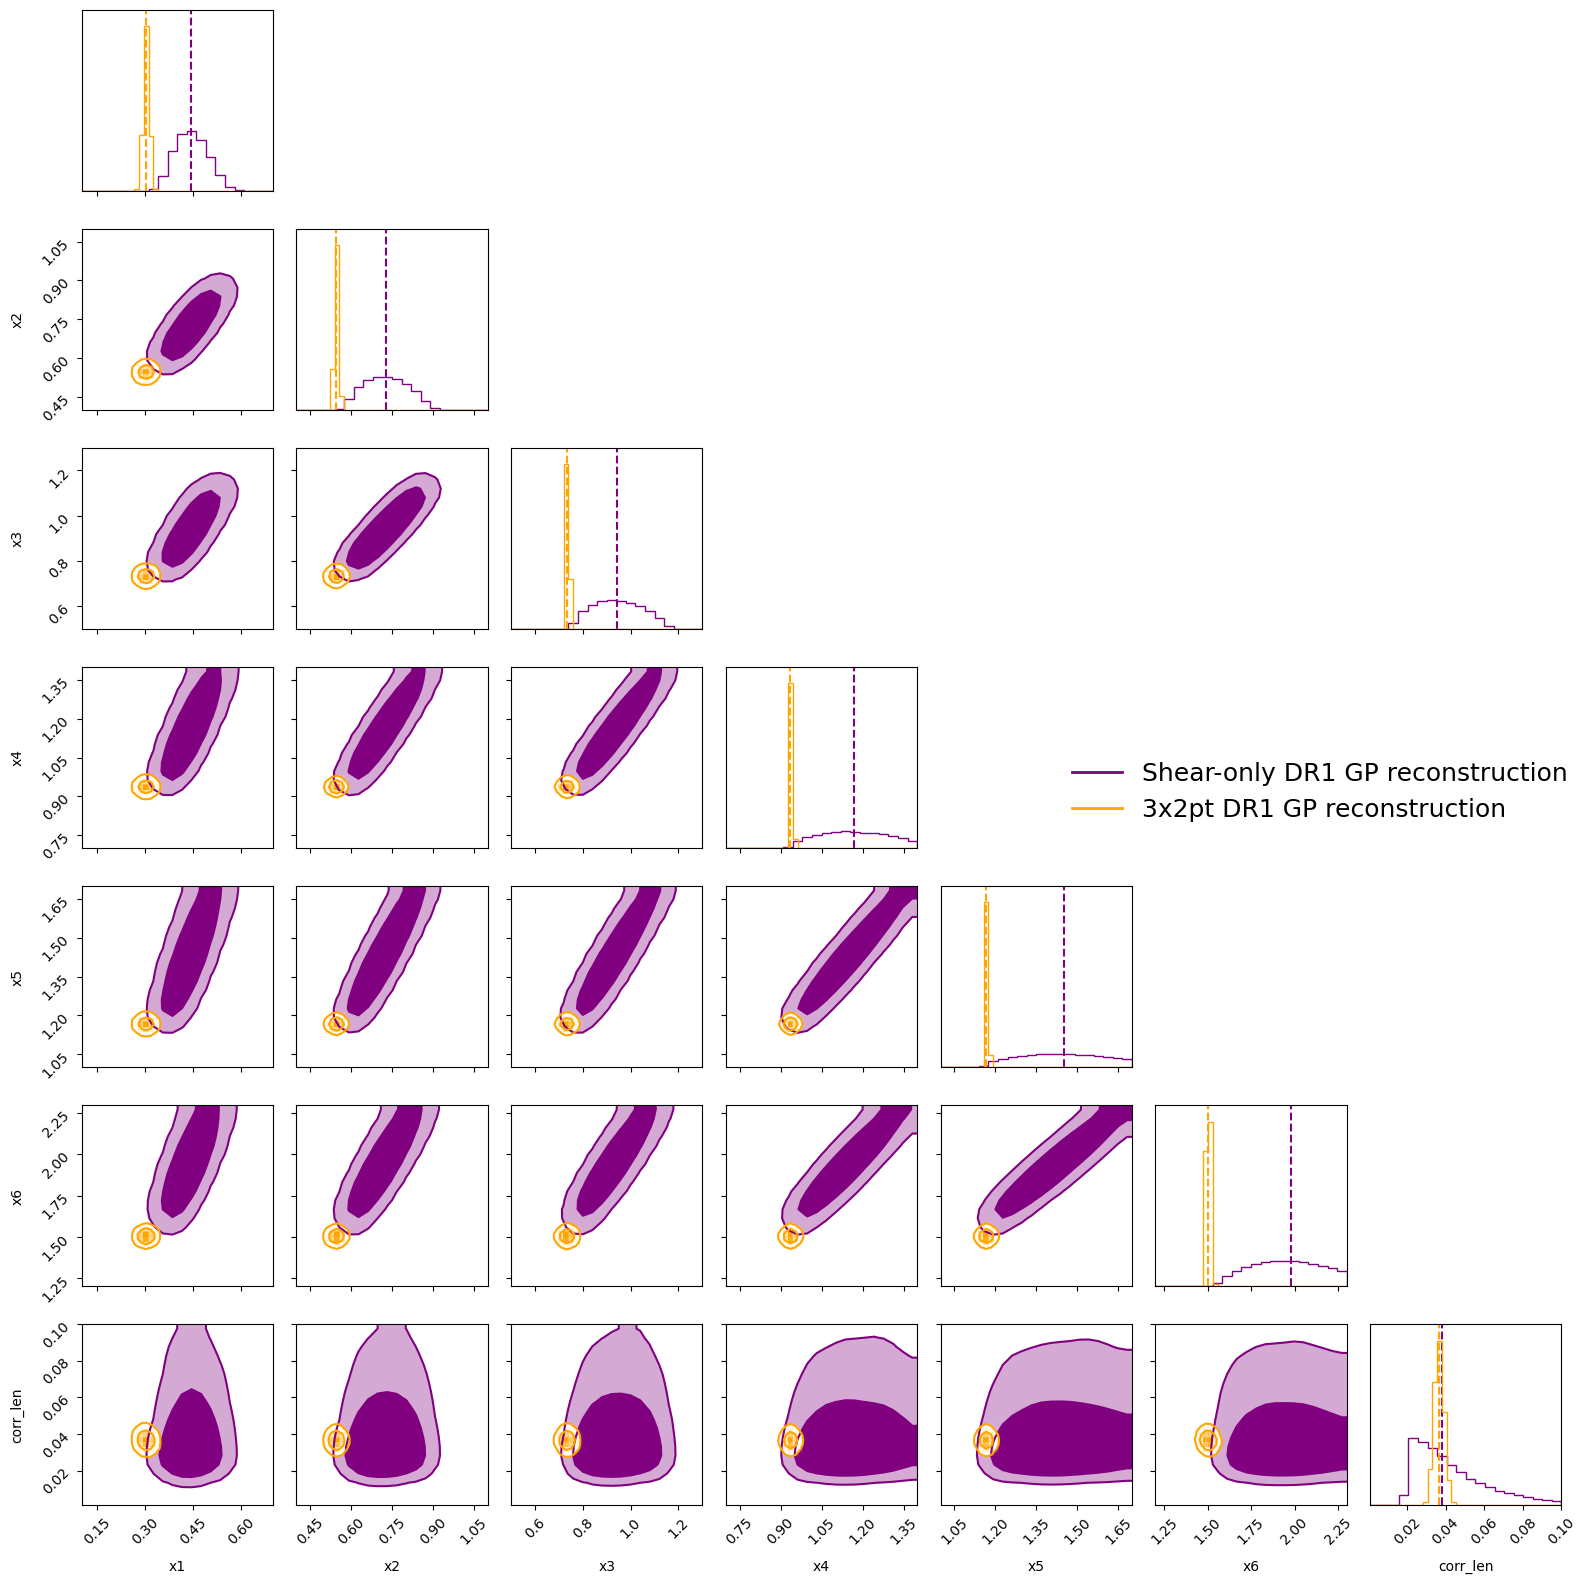

In [29]:
# Plotting WL GP and 3x2pt GP w0wa GP parameters #

names_gp = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'corr_len']
names_gp_3x2pt = ['x1_she', 'x2_she', 'x3_she', 'x4_she', 'x5_she', 'x6_she', 'corr_len_she']
ranges = [(0.1, 0.7), (0.4, 1.1), (0.5, 1.3), (0.7, 1.4), (1, 1.7), (1.2, 2.3), (0.001, 0.1)]
points_gp_WL = np.column_stack([dict_chains["w0wa_GP_WL"][p] for p in names_gp])
points_gp_3x2pt = np.column_stack([dict_chains["w0wa_GP_3x2pt"][p] for p in names_gp_3x2pt])
log_w_gp_WL = dict_data["w0wa_GP_WL"]["weights"]
log_w_gp_3x2pt = dict_data["w0wa_GP_3x2pt"]["weights"]
fig = corner.corner(
    points_gp_WL, weights=np.exp(log_w_gp_WL), bins=20, labels=names_gp, color='purple', linewidth=2,
    plot_datapoints=False, fill_contours=True, smooth=1.0, quantiles=[0.5], range=ranges, levels=(0.68, 0.95))
corner.corner(
    points_gp_3x2pt, weights=np.exp(log_w_gp_3x2pt), bins=40, color='orange', labels=names_gp, linewidth=2,
    plot_datapoints=False, fill_contours=False, smooth=1.0, quantiles=[0.5], range=ranges, levels=(0.68, 0.95), fig=fig)
line1 = mlines.Line2D([], [], color="purple", lw=2, label="Shear-only DR1 GP reconstruction")
line2 = mlines.Line2D([], [], color="orange", lw=2, label="3x2pt DR1 GP reconstruction")
fig.legend(
    handles=[line1, line2],
    loc="center right",
    frameon=False, fontsize=18
)
plt.tight_layout()

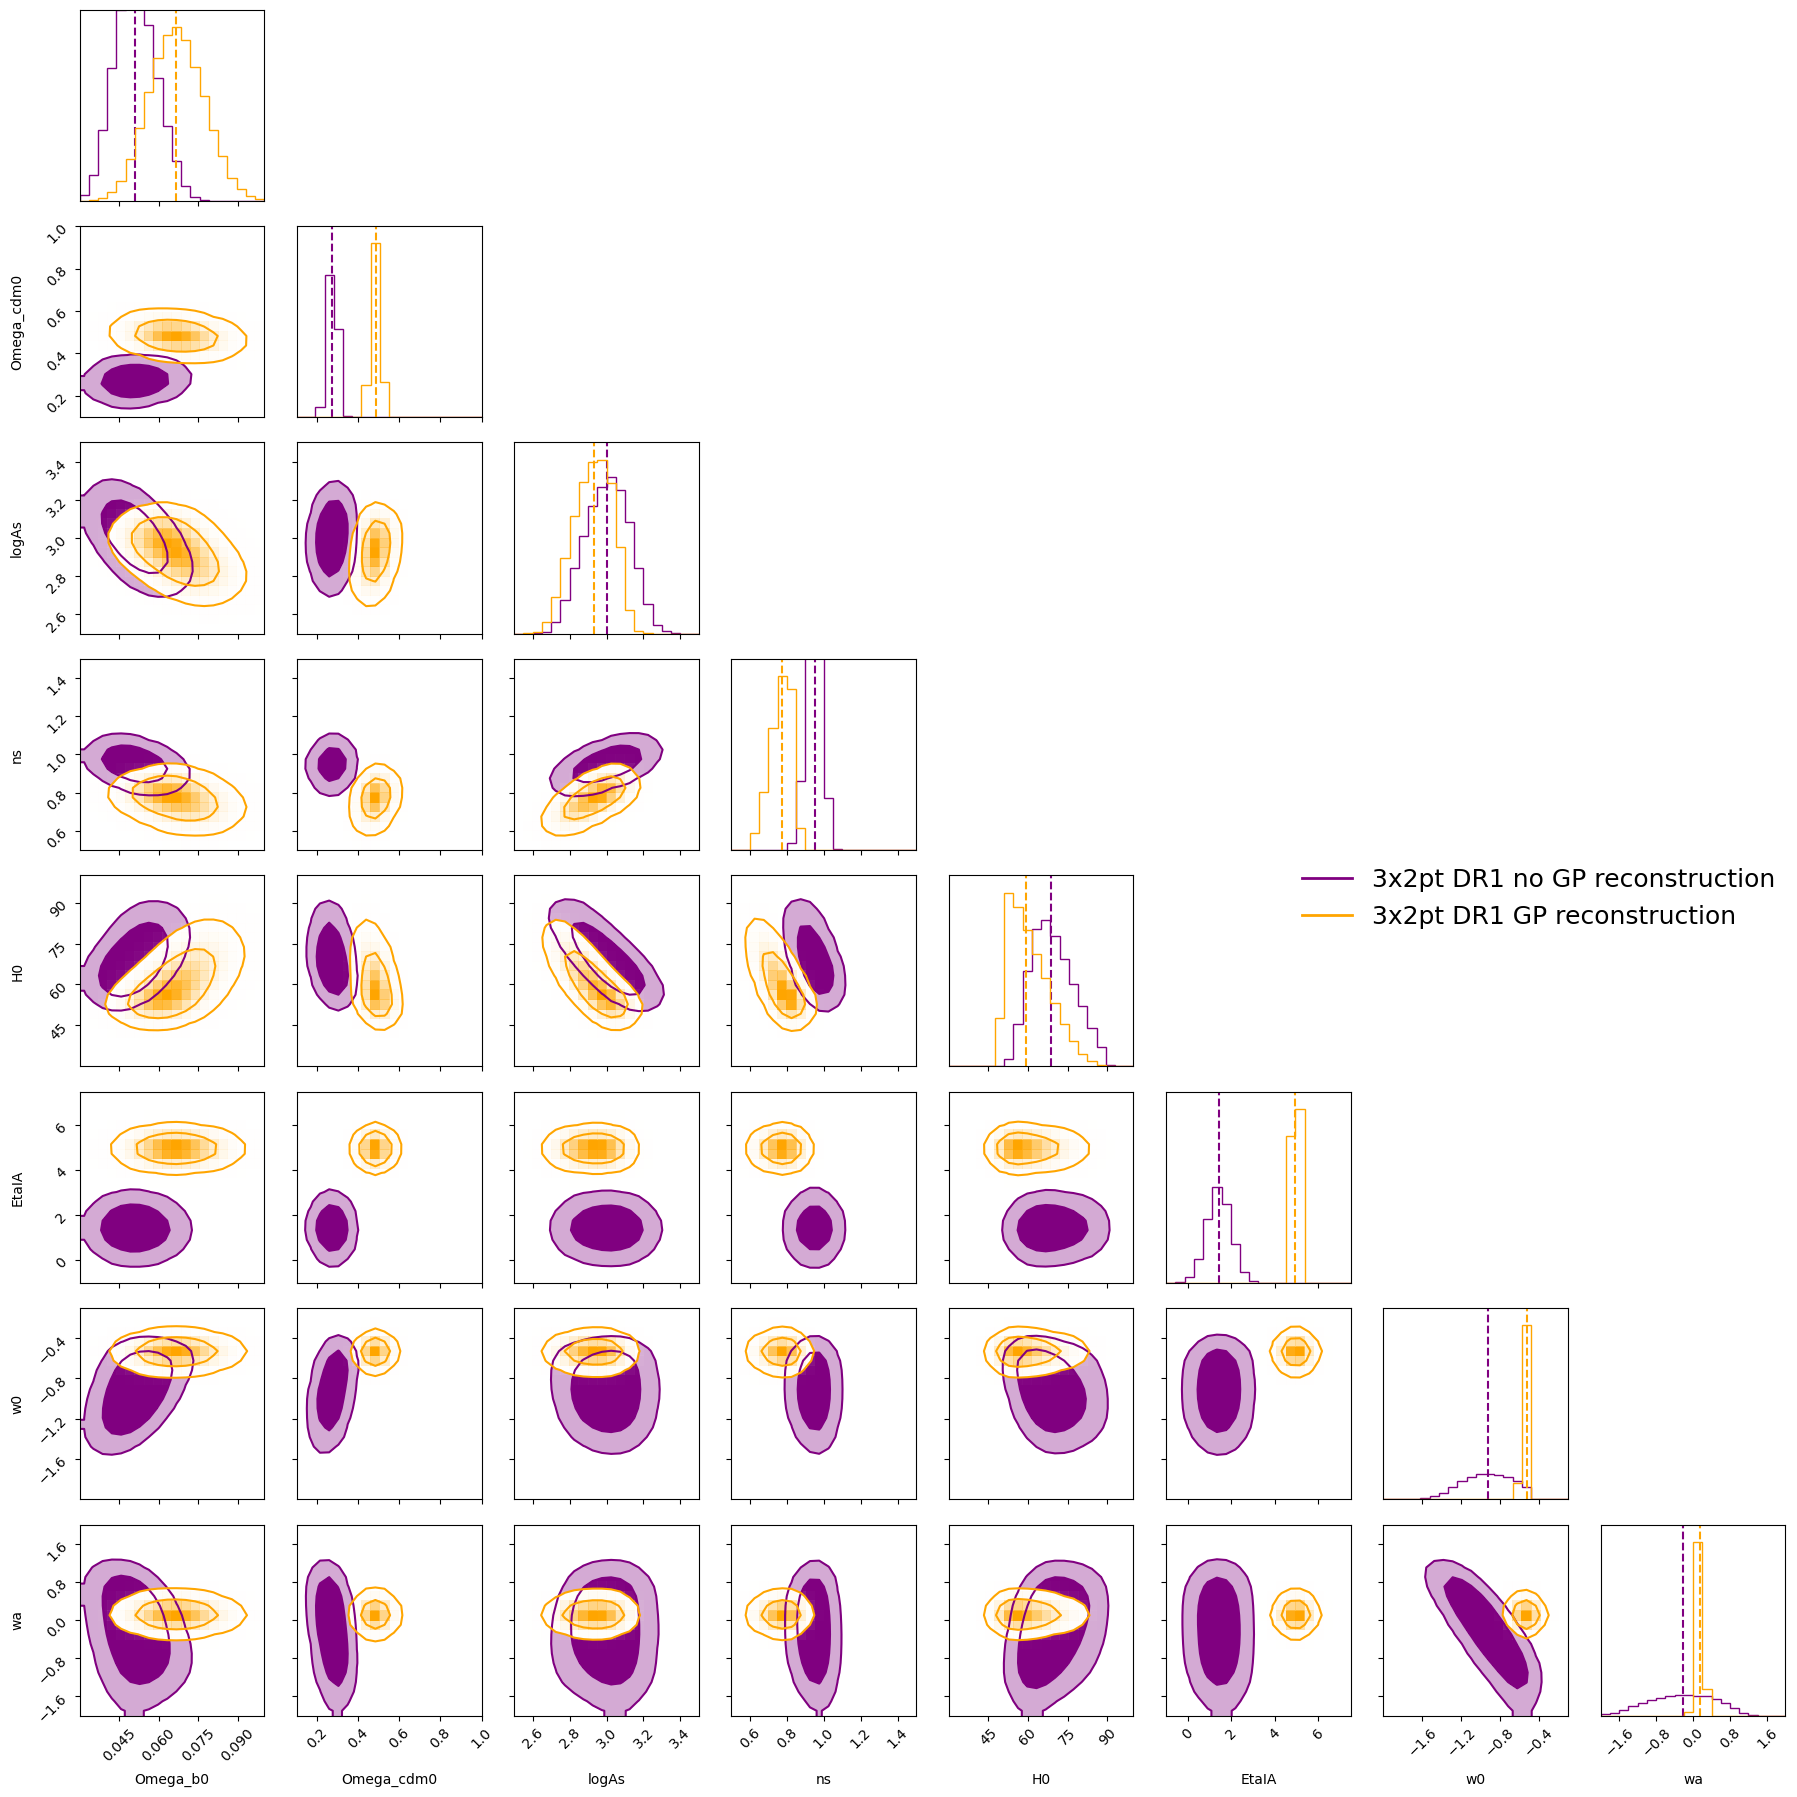

In [39]:
# Plotting 3x2pt GP and no GP posteriors in a single corner plot using corner #

points_3x2pt = np.column_stack([dict_chains["w0wa_3x2pt"][p] for p in names_chain])
points_gp_3x2pt = np.column_stack([dict_chains["w0wa_GP_3x2pt"][p] for p in names_chain])
log_w_3x2pt = dict_data["w0wa_3x2pt"]["weights"]
log_w_gp_3x2pt = dict_data["w0wa_GP_3x2pt"]["weights"]
range_3x2pt = [(0.03, 0.1), (0.1, 1), (2.5, 3.5), (0.5, 1.5), (30, 100), (-1, 7.5), (-2, -0.1), (-2,2)]

fig = corner.corner(
    points_3x2pt, weights=np.exp(log_w_3x2pt), bins=20, labels=names_chain, color='purple', linewidth=2,
    plot_datapoints=False, fill_contours=True, smooth=1.0, quantiles=[0.5], range=range_3x2pt, levels=(0.68, 0.95))
corner.corner(
    points_gp_3x2pt, weights=np.exp(log_w_gp_3x2pt), bins=20, color='orange', labels=names_chain, linewidth=2,
    plot_datapoints=False, fill_contours=False, smooth=1.0, quantiles=[0.5], range=range_3x2pt, levels=(0.68, 0.95), fig=fig)
line1 = mlines.Line2D([], [], color="purple", lw=2, label="3x2pt DR1 no GP reconstruction")
line2 = mlines.Line2D([], [], color="orange", lw=2, label="3x2pt DR1 GP reconstruction")
fig.legend(
    handles=[line1, line2],
    loc="center right",
    frameon=False, fontsize=18
)
plt.tight_layout()

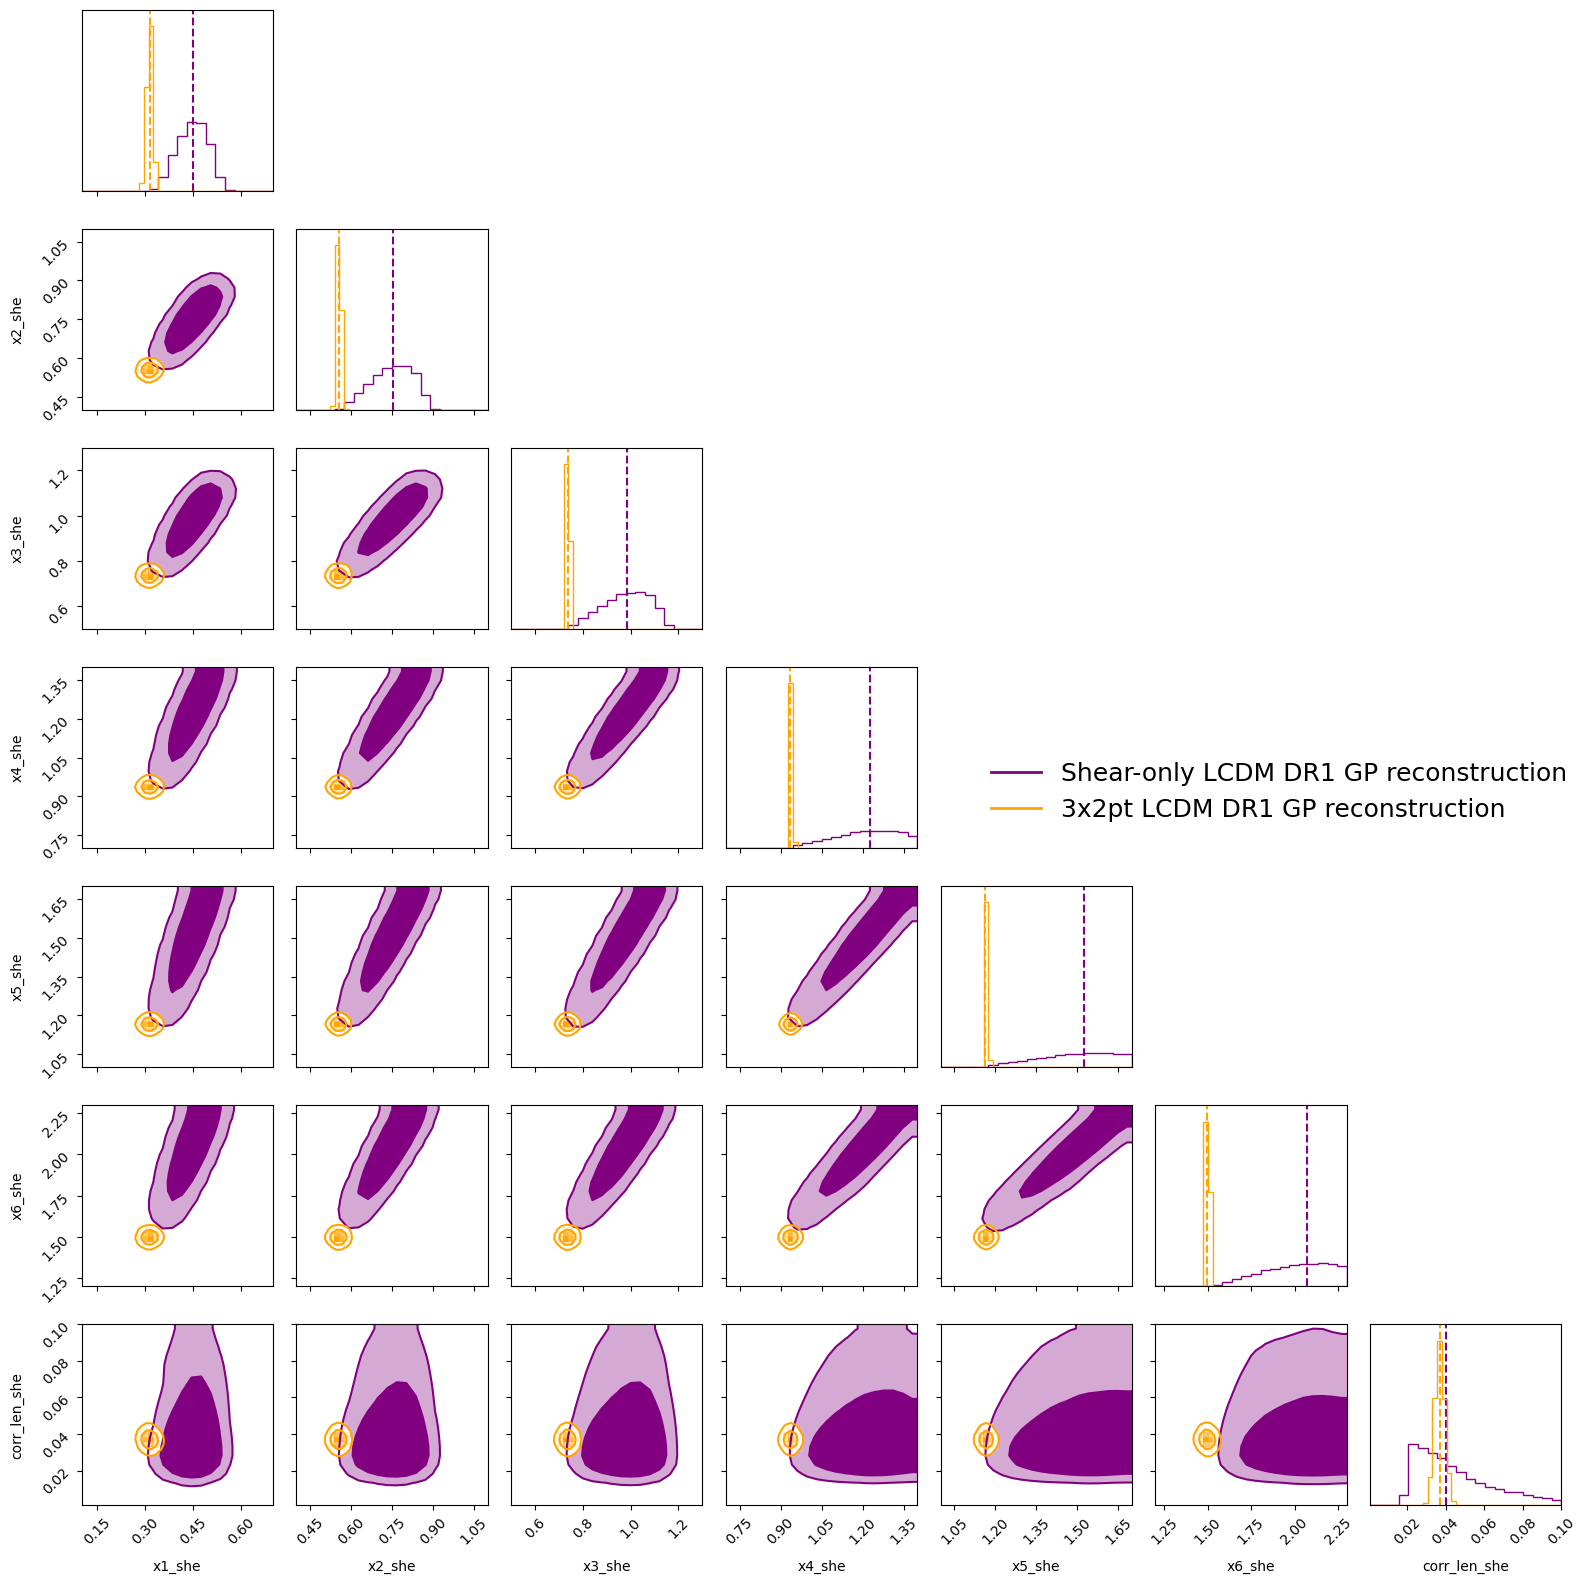

In [44]:
# Plotting WL GP and 3x2pt GP LCDM GP parameters #

names_gp = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'corr_len']
names_gp_3x2pt = ['x1_she', 'x2_she', 'x3_she', 'x4_she', 'x5_she', 'x6_she', 'corr_len_she']
ranges = [(0.1, 0.7), (0.4, 1.1), (0.5, 1.3), (0.7, 1.4), (1, 1.7), (1.2, 2.3), (0.001, 0.1)]
points_gp_WL_LCDM = np.column_stack([dict_chains["LCDM_GP_WL"][p] for p in names_gp])
points_gp_3x2pt_LCDM = np.column_stack([dict_chains["LCDM_GP_3x2pt"][p] for p in names_gp_3x2pt])
log_w_gp_WL_LCDM = dict_data["LCDM_GP_WL"]["weights"]
log_w_gp_3x2pt_LCDM = dict_data["LCDM_GP_3x2pt"]["weights"]
fig = corner.corner(
    points_gp_WL_LCDM, weights=np.exp(log_w_gp_WL_LCDM), bins=20, labels=names_gp, color='purple', linewidth=2,
    plot_datapoints=False, fill_contours=True, smooth=1.0, quantiles=[0.5], range=ranges, levels=(0.68, 0.95))
corner.corner(
    points_gp_3x2pt_LCDM, weights=np.exp(log_w_gp_3x2pt_LCDM), bins=40, color='orange', labels=names_gp_3x2pt, linewidth=2,
    plot_datapoints=False, fill_contours=False, smooth=1.0, quantiles=[0.5], range=ranges, levels=(0.68, 0.95), fig=fig)
line1 = mlines.Line2D([], [], color="purple", lw=2, label="Shear-only LCDM DR1 GP reconstruction")
line2 = mlines.Line2D([], [], color="orange", lw=2, label="3x2pt LCDM DR1 GP reconstruction")
fig.legend(
    handles=[line1, line2],
    loc="center right",
    frameon=False, fontsize=18
)
plt.tight_layout()

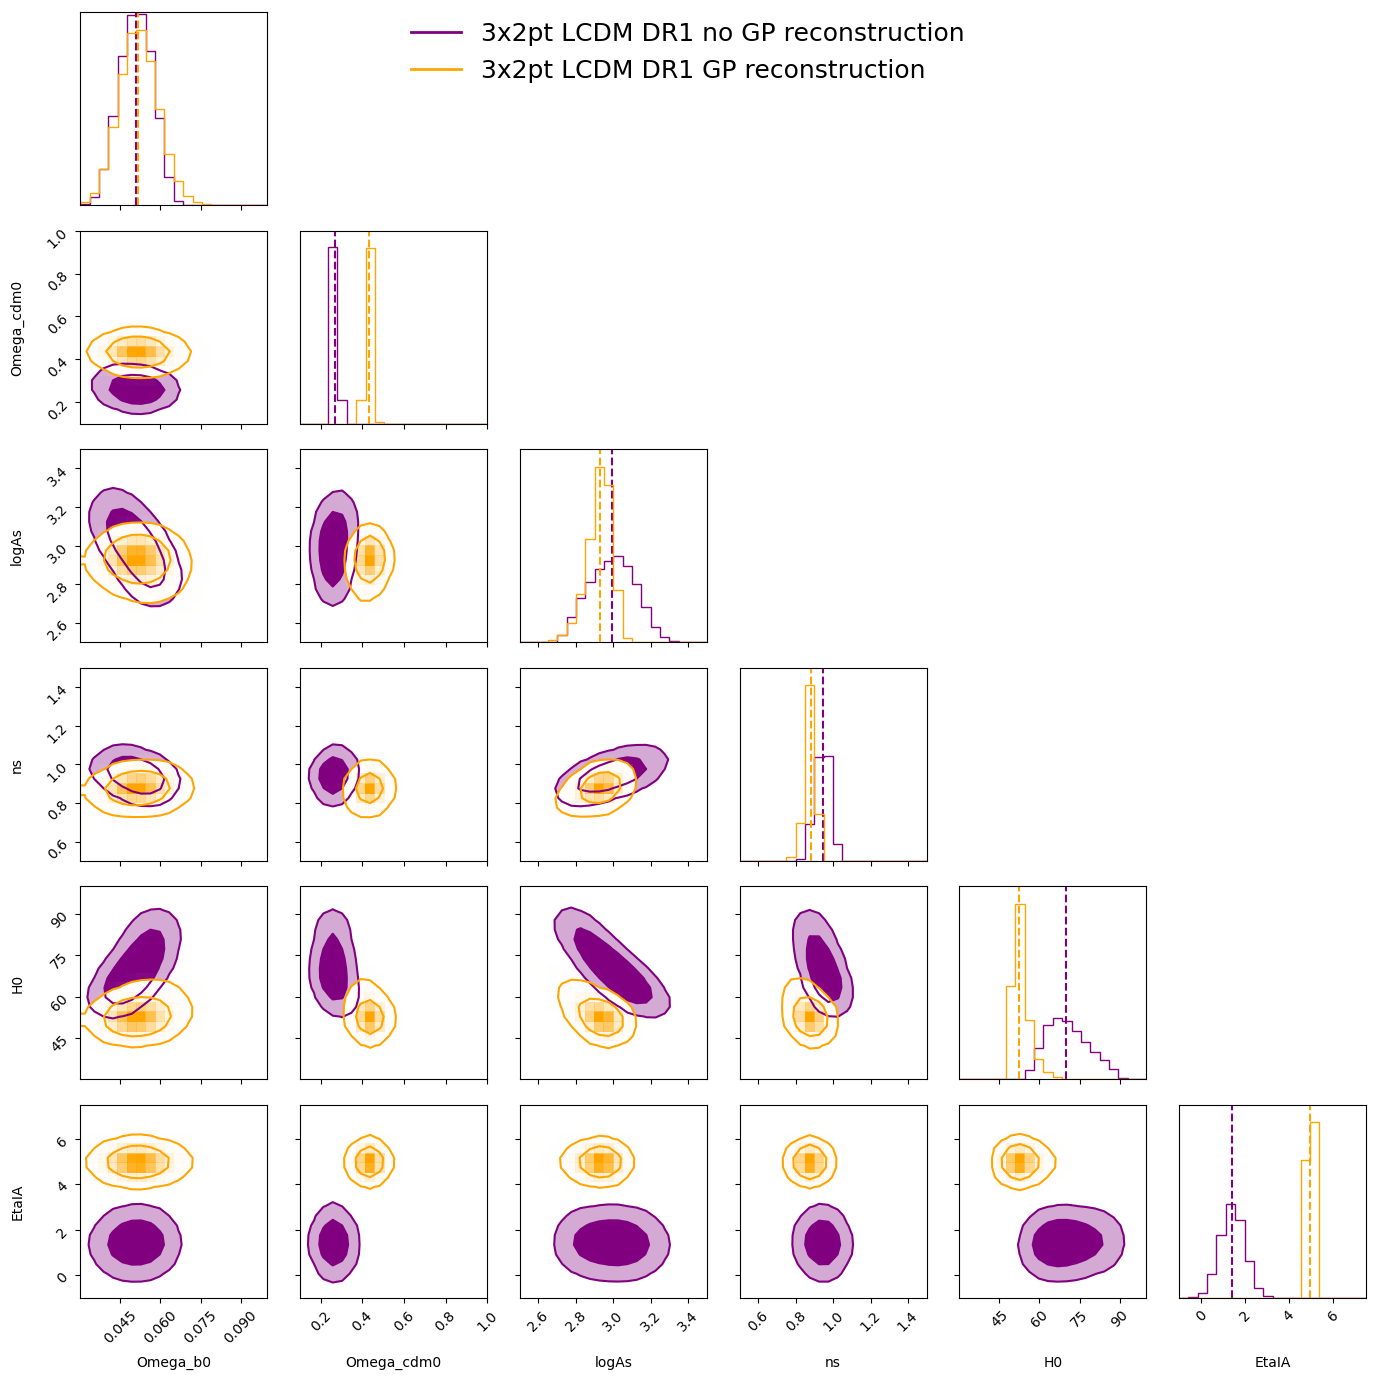

In [46]:
# Plotting 3x2pt GP and no GP LCDM posteriors in a single corner plot using corner #

names_chain_LCDM = ['Omega_b0', 'Omega_cdm0', 'logAs', 'ns', 'H0', 'EtaIA']
points_3x2pt_LCDM = np.column_stack([dict_chains["LCDM_3x2pt"][p] for p in names_chain_LCDM])
points_gp_3x2pt_LCDM = np.column_stack([dict_chains["LCDM_GP_3x2pt"][p] for p in names_chain_LCDM])
log_w_3x2pt_LCDM = dict_data["LCDM_3x2pt"]["weights"]
log_w_gp_3x2pt_LCDM = dict_data["LCDM_GP_3x2pt"]["weights"]
range_3x2pt_LCDM = [(0.03, 0.1), (0.1, 1), (2.5, 3.5), (0.5, 1.5), (30, 100), (-1, 7.5)]

fig = corner.corner(
    points_3x2pt_LCDM, weights=np.exp(log_w_3x2pt_LCDM), bins=20, labels=names_chain_LCDM, color='purple', linewidth=2,
    plot_datapoints=False, fill_contours=True, smooth=1.0, quantiles=[0.5], range=range_3x2pt_LCDM, levels=(0.68, 0.95))
corner.corner(
    points_gp_3x2pt_LCDM, weights=np.exp(log_w_gp_3x2pt_LCDM), bins=20, color='orange', labels=names_chain_LCDM, linewidth=2,
    plot_datapoints=False, fill_contours=False, smooth=1.0, quantiles=[0.5], range=range_3x2pt_LCDM, levels=(0.68, 0.95), fig=fig)
line1 = mlines.Line2D([], [], color="purple", lw=2, label="3x2pt LCDM DR1 no GP reconstruction")
line2 = mlines.Line2D([], [], color="orange", lw=2, label="3x2pt LCDM DR1 GP reconstruction")
fig.legend(
    handles=[line1, line2],
    loc="upper center",
    frameon=False, fontsize=18
)
plt.tight_layout()

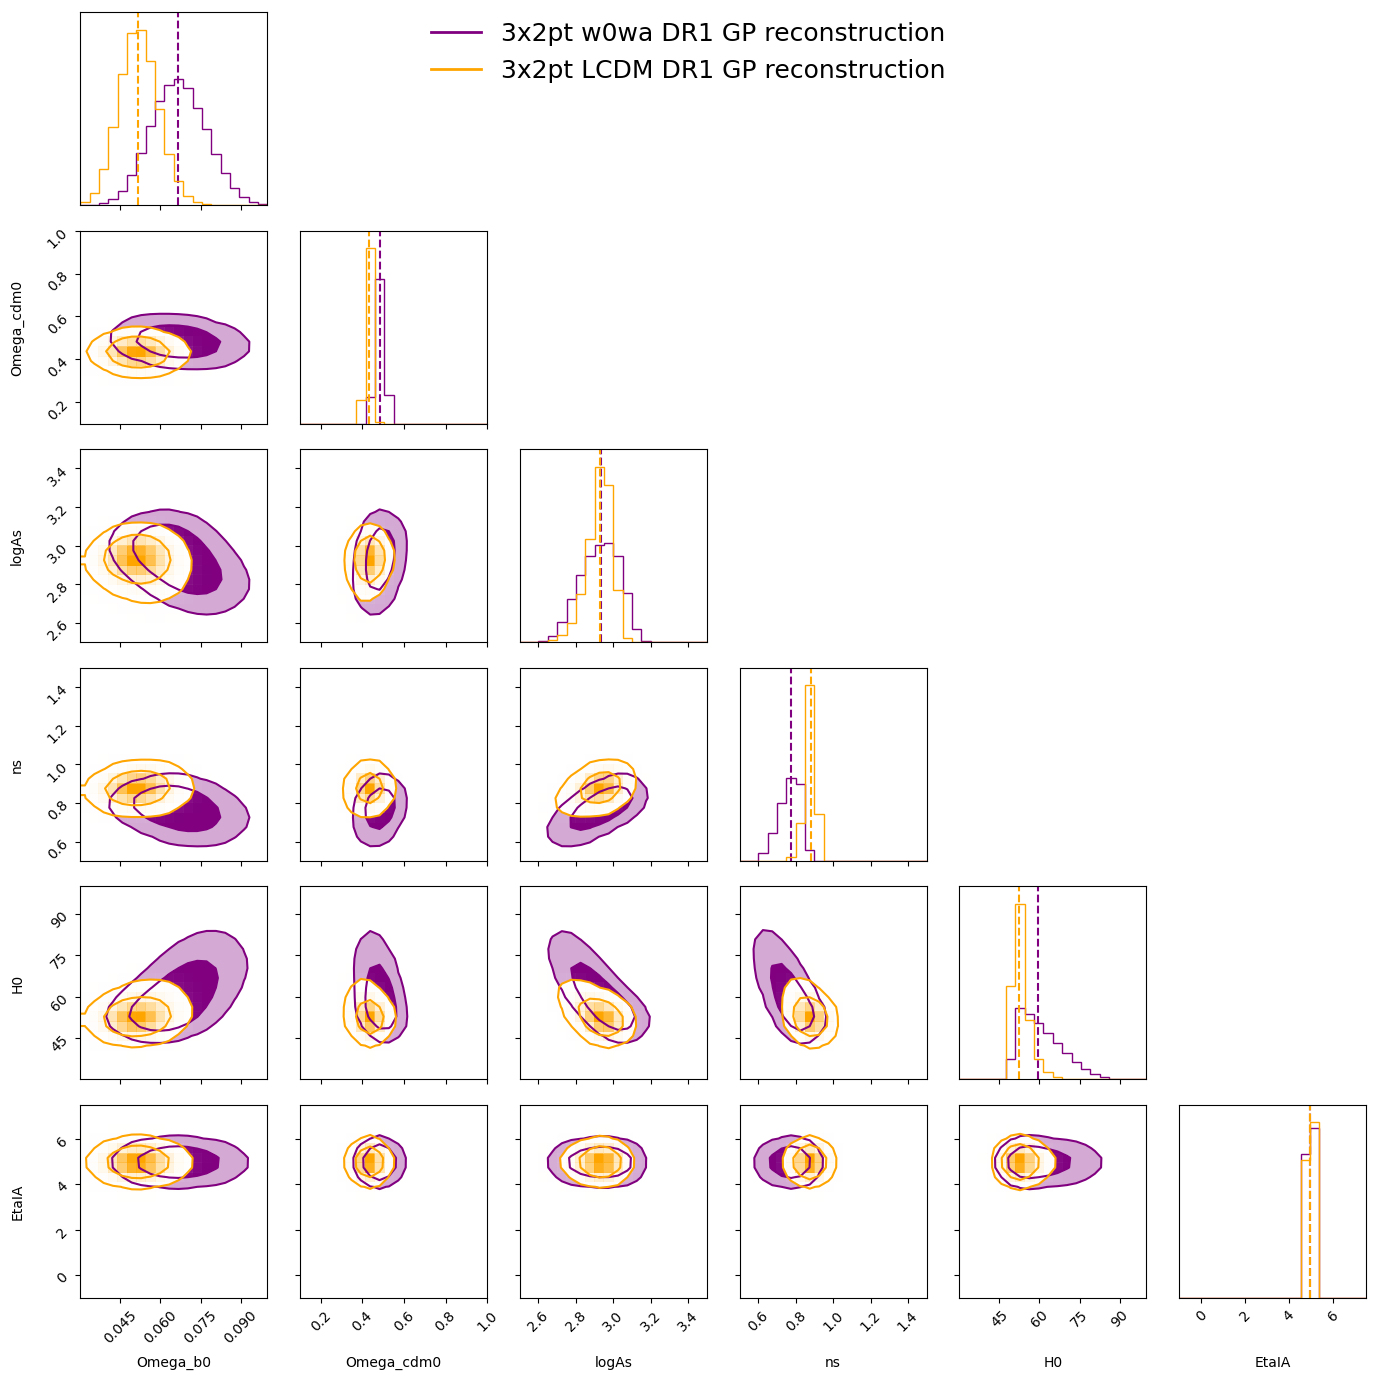

In [47]:
# Plotting 3x2pt GP LCDM and w0wa posteriors in a single corner plot using corner #

names_chain_LCDM = ['Omega_b0', 'Omega_cdm0', 'logAs', 'ns', 'H0', 'EtaIA']
points_gp_3x2pt_w0wa = np.column_stack([dict_chains["w0wa_GP_3x2pt"][p] for p in names_chain_LCDM])
points_gp_3x2pt_LCDM = np.column_stack([dict_chains["LCDM_GP_3x2pt"][p] for p in names_chain_LCDM])
log_w_gp_3x2pt_w0wa = dict_data["w0wa_GP_3x2pt"]["weights"]
log_w_gp_3x2pt_LCDM = dict_data["LCDM_GP_3x2pt"]["weights"]
range_3x2pt_LCDM = [(0.03, 0.1), (0.1, 1), (2.5, 3.5), (0.5, 1.5), (30, 100), (-1, 7.5)]

fig = corner.corner(
    points_gp_3x2pt_w0wa, weights=np.exp(log_w_gp_3x2pt_w0wa), bins=20, labels=names_chain_LCDM, color='purple', linewidth=2,
    plot_datapoints=False, fill_contours=True, smooth=1.0, quantiles=[0.5], range=range_3x2pt_LCDM, levels=(0.68, 0.95))
corner.corner(
    points_gp_3x2pt_LCDM, weights=np.exp(log_w_gp_3x2pt_LCDM), bins=20, color='orange', labels=names_chain_LCDM, linewidth=2,
    plot_datapoints=False, fill_contours=False, smooth=1.0, quantiles=[0.5], range=range_3x2pt_LCDM, levels=(0.68, 0.95), fig=fig)
line1 = mlines.Line2D([], [], color="purple", lw=2, label="3x2pt w0wa DR1 GP reconstruction")
line2 = mlines.Line2D([], [], color="orange", lw=2, label="3x2pt LCDM DR1 GP reconstruction")
fig.legend(
    handles=[line1, line2],
    loc="upper center",
    frameon=False, fontsize=18
)
plt.tight_layout()

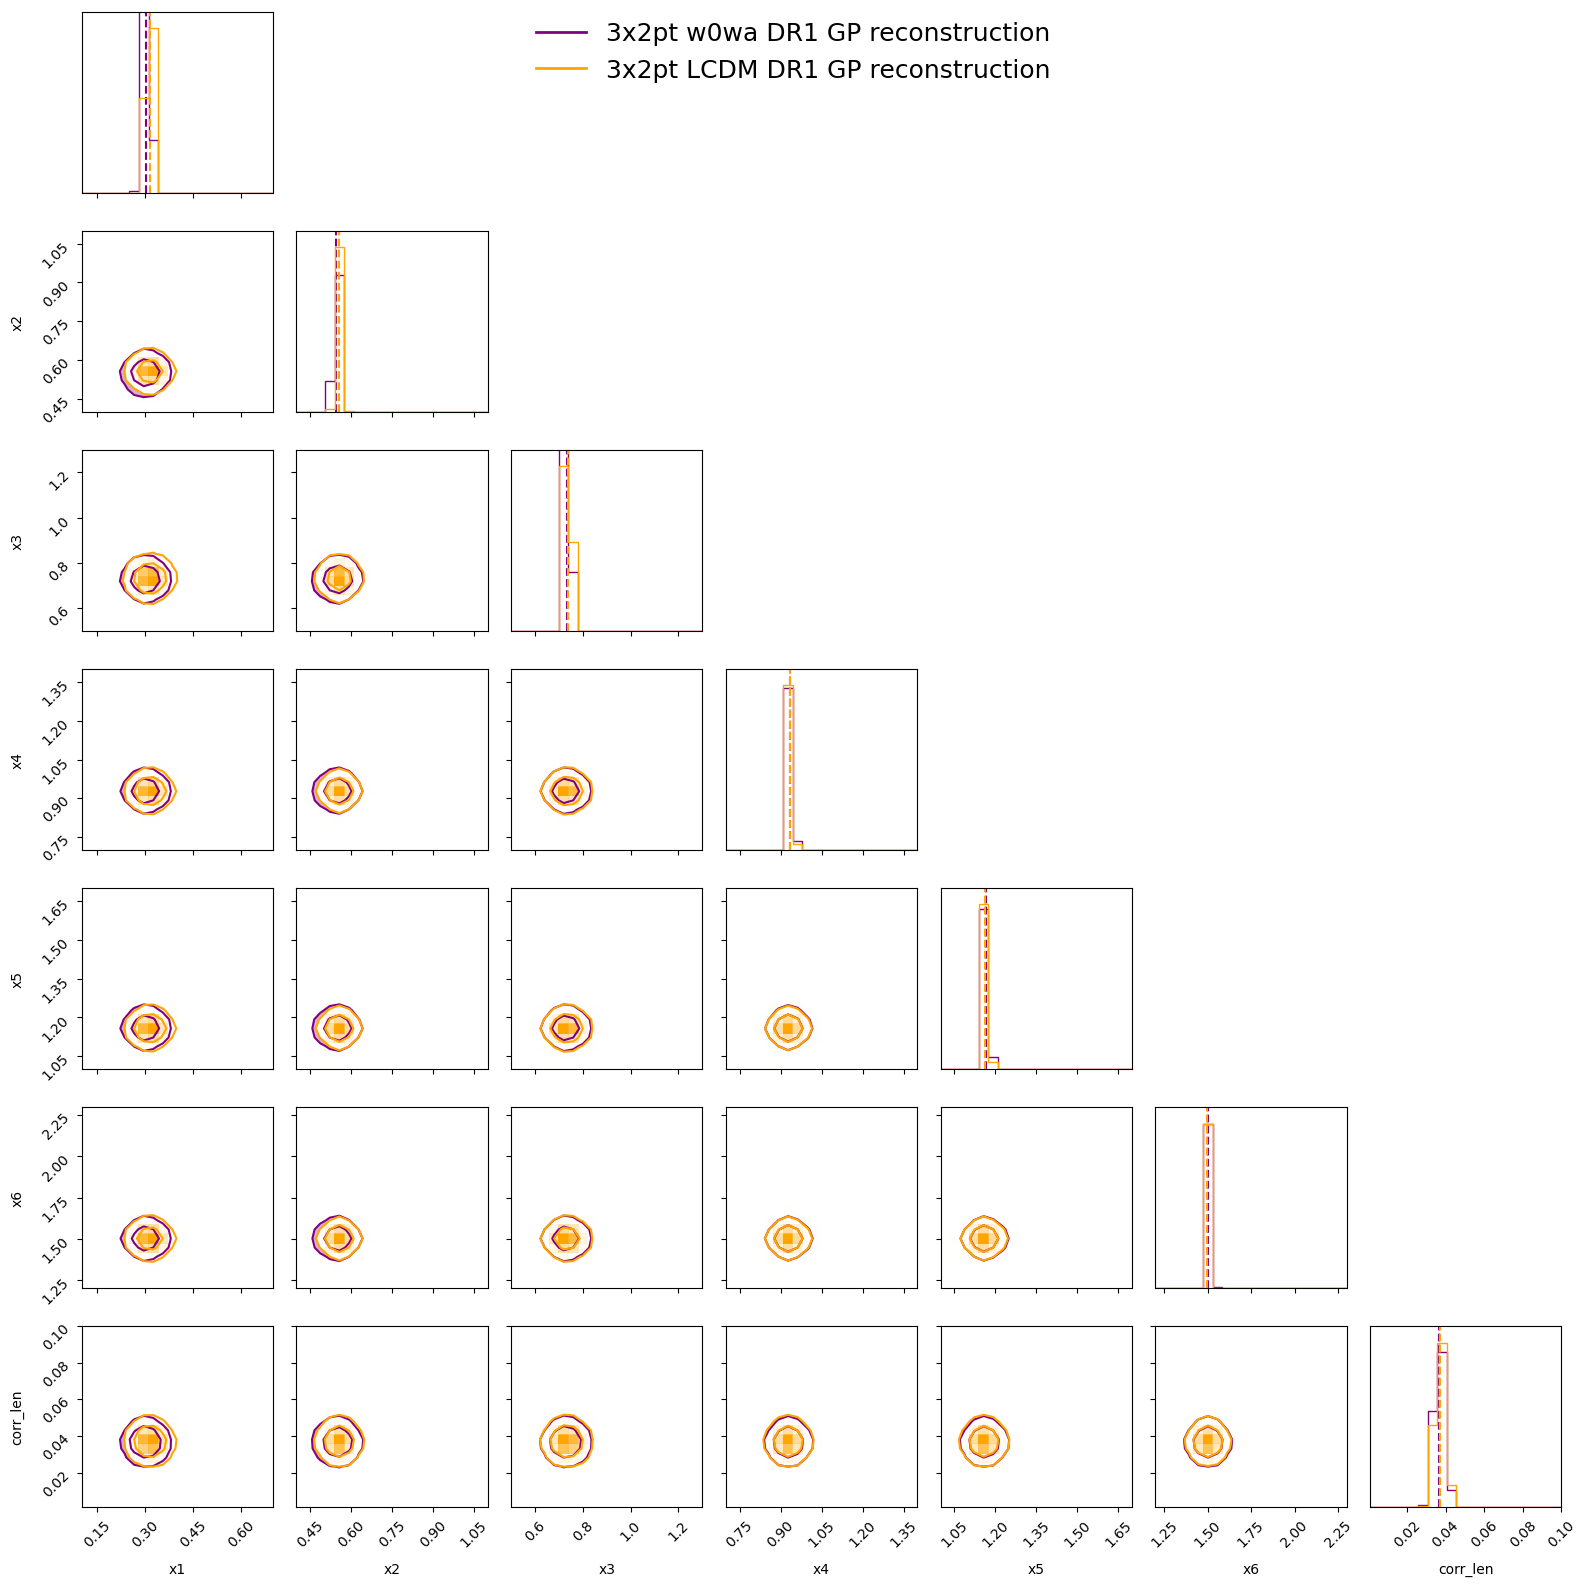

In [49]:
# Plotting 3x2pt GP LCDM and w0wa GP parameters posteriors in a single corner plot using corner #

points_gp_3x2pt_w0wa = np.column_stack([dict_chains["w0wa_GP_3x2pt"][p] for p in names_gp_3x2pt])
points_gp_3x2pt_LCDM = np.column_stack([dict_chains["LCDM_GP_3x2pt"][p] for p in names_gp_3x2pt])
log_w_gp_3x2pt_w0wa = dict_data["w0wa_GP_3x2pt"]["weights"]
log_w_gp_3x2pt_LCDM = dict_data["LCDM_GP_3x2pt"]["weights"]
range_3x2pt_LCDM = [(0.03, 0.1), (0.1, 1), (2.5, 3.5), (0.5, 1.5), (30, 100), (-1, 7.5)]

fig = corner.corner(
    points_gp_3x2pt_w0wa, weights=np.exp(log_w_gp_3x2pt_w0wa), bins=20, labels=names_gp, color='purple', linewidth=2,
    plot_datapoints=False, fill_contours=True, smooth=1.0, quantiles=[0.5], range=ranges, levels=(0.68, 0.95))
corner.corner(
    points_gp_3x2pt_LCDM, weights=np.exp(log_w_gp_3x2pt_LCDM), bins=20, color='orange', labels=names_gp, linewidth=2,
    plot_datapoints=False, fill_contours=False, smooth=1.0, quantiles=[0.5], range=ranges, levels=(0.68, 0.95), fig=fig)
line1 = mlines.Line2D([], [], color="purple", lw=2, label="3x2pt w0wa DR1 GP reconstruction")
line2 = mlines.Line2D([], [], color="orange", lw=2, label="3x2pt LCDM DR1 GP reconstruction")
fig.legend(
    handles=[line1, line2],
    loc="upper center",
    frameon=False, fontsize=18
)
plt.tight_layout()